Constructing a Temporal Network from the Sensor Data

In [3]:
# import necessary packages
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

In [33]:
# import the sensor data and give it new column names based on the SocioPatterns data base  

sensor_data = pl.read_csv("/Users/maggiebothwell/Documents/GitHub/Project-Repository/Data/Raw/HighSchool2013_proximity_net.csv",
    separator=" ",
    has_header=False,
    new_columns=["t", "i", "j", "Ci", "Cj"],
)

# verify the data was correctly imported with header names
print(sensor_data)

shape: (188_508, 5)
┌────────────┬─────┬─────┬───────┬───────┐
│ t          ┆ i   ┆ j   ┆ Ci    ┆ Cj    │
│ ---        ┆ --- ┆ --- ┆ ---   ┆ ---   │
│ i64        ┆ i64 ┆ i64 ┆ str   ┆ str   │
╞════════════╪═════╪═════╪═══════╪═══════╡
│ 1385982020 ┆ 454 ┆ 640 ┆ MP    ┆ MP    │
│ 1385982020 ┆ 1   ┆ 939 ┆ 2BIO3 ┆ 2BIO3 │
│ 1385982020 ┆ 185 ┆ 258 ┆ PC*   ┆ PC*   │
│ 1385982020 ┆ 55  ┆ 170 ┆ 2BIO3 ┆ 2BIO3 │
│ 1385982020 ┆ 9   ┆ 453 ┆ PC    ┆ PC    │
│ …          ┆ …   ┆ …   ┆ …     ┆ …     │
│ 1386345560 ┆ 120 ┆ 285 ┆ PC    ┆ PC    │
│ 1386345580 ┆ 61  ┆ 160 ┆ 2BIO2 ┆ 2BIO2 │
│ 1386345580 ┆ 272 ┆ 939 ┆ 2BIO3 ┆ 2BIO3 │
│ 1386345580 ┆ 311 ┆ 496 ┆ PC    ┆ PC    │
│ 1386345580 ┆ 120 ┆ 285 ┆ PC    ┆ PC    │
└────────────┴─────┴─────┴───────┴───────┘


In [34]:
# we will not need the class data, so making a new dataframe without the class columns
interactions = sensor_data.drop(["Ci", "Cj"])

# verify the new dataframe was correctly created without the class columns
print(interactions)

shape: (188_508, 3)
┌────────────┬─────┬─────┐
│ t          ┆ i   ┆ j   │
│ ---        ┆ --- ┆ --- │
│ i64        ┆ i64 ┆ i64 │
╞════════════╪═════╪═════╡
│ 1385982020 ┆ 454 ┆ 640 │
│ 1385982020 ┆ 1   ┆ 939 │
│ 1385982020 ┆ 185 ┆ 258 │
│ 1385982020 ┆ 55  ┆ 170 │
│ 1385982020 ┆ 9   ┆ 453 │
│ …          ┆ …   ┆ …   │
│ 1386345560 ┆ 120 ┆ 285 │
│ 1386345580 ┆ 61  ┆ 160 │
│ 1386345580 ┆ 272 ┆ 939 │
│ 1386345580 ┆ 311 ┆ 496 │
│ 1386345580 ┆ 120 ┆ 285 │
└────────────┴─────┴─────┘


In [37]:
# Store a list of all unique timestamps in chronological order
timestamps = interactions["t"].unique().sort()
print(timestamps) # the shape of this indicates that there are 7375 unique time stamps

# Start an empty dictionary which will store the interactions that occur for each time stamp
interactions_by_time = {}

# for each entry in the list of unique timestamps, filter the interactions dataframe to get only the 
# interactions that occur at that timestamp and save this in the dictionary 
for timestamp in timestamps:
    # at the timestamp of the current iteration of the loop, select only the rows that 
    # satisfy the condition that the timestamp column matches the current timestamp of the loop,
    # and store the filtered dataframe in the dictionary with the timestamp as the key
    interactions_by_time[timestamp] = interactions.filter(pl.col("t") == timestamp)

# verify the dictionary was correctly created with interactions grouped by timestamp
print(interactions_by_time)

shape: (7_375,)
Series: 't' [i64]
[
	1385982020
	1385982040
	1385982060
	1385982080
	1385982100
	…
	1386345500
	1386345520
	1386345540
	1386345560
	1386345580
]
{1385982020: shape: (35, 3)
┌────────────┬──────┬──────┐
│ t          ┆ i    ┆ j    │
│ ---        ┆ ---  ┆ ---  │
│ i64        ┆ i64  ┆ i64  │
╞════════════╪══════╪══════╡
│ 1385982020 ┆ 454  ┆ 640  │
│ 1385982020 ┆ 1    ┆ 939  │
│ 1385982020 ┆ 185  ┆ 258  │
│ 1385982020 ┆ 55   ┆ 170  │
│ 1385982020 ┆ 9    ┆ 453  │
│ …          ┆ …    ┆ …    │
│ 1385982020 ┆ 1238 ┆ 1260 │
│ 1385982020 ┆ 487  ┆ 984  │
│ 1385982020 ┆ 226  ┆ 353  │
│ 1385982020 ┆ 1342 ┆ 1518 │
│ 1385982020 ┆ 122  ┆ 255  │
└────────────┴──────┴──────┘, 1385982040: shape: (37, 3)
┌────────────┬──────┬──────┐
│ t          ┆ i    ┆ j    │
│ ---        ┆ ---  ┆ ---  │
│ i64        ┆ i64  ┆ i64  │
╞════════════╪══════╪══════╡
│ 1385982040 ┆ 454  ┆ 640  │
│ 1385982040 ┆ 1    ┆ 939  │
│ 1385982040 ┆ 185  ┆ 258  │
│ 1385982040 ┆ 1067 ┆ 1324 │
│ 1385982040 ┆ 70   ┆ 132  │


1385982020


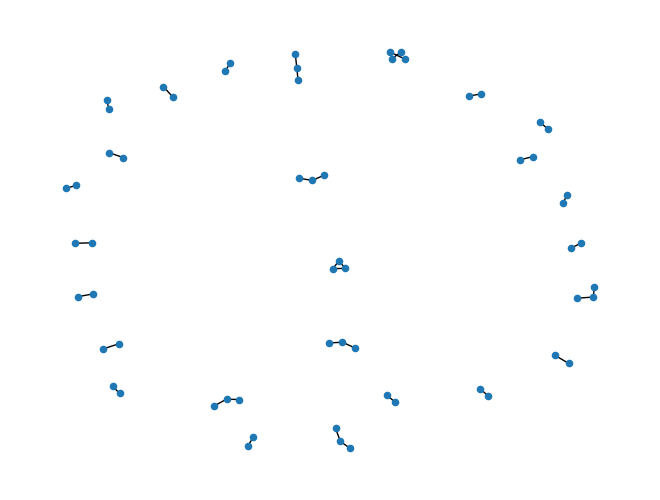

In [38]:
# creating the network for the first timestamp before iterating over every timestamp

print(timestamps[0]) # the first timestamp in the list of unique timestamps is 1385982020
interactions_1385982020 = interactions_by_time[1385982020]

G_1385982020 = nx.from_pandas_edgelist(interactions_1385982020, "i", "j")
nx.draw(G_1385982020, node_size = 20)

In [39]:
# now, loop for every timestamp to create a network for each timestamp

# create an empty dictionary to store the networks for each timestamp
networks_by_time = {}

for timestamp in timestamps:
    interactions_at_timestamp = interactions_by_time[timestamp]
    G_at_timestamp = nx.from_pandas_edgelist(interactions_at_timestamp, "i", "j")
    networks_by_time[timestamp] = G_at_timestamp

print(len(networks_by_time))  # this confirms that 7375 unique networks were made, to represent each unique timestamp

7375


```networks_by_time``` Represents the temporal network.

To print a network at a specific timestamp: ```nx.draw(networks_by_time[timestamp], node_size = 20)```, replacing "timestamp" with the numerical timestamp

In [40]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Start with the first 50 timestamps.
times_to_show = sorted(networks_by_time)[:50]

# Combine these snapshots only to choose consistent node positions.
layout_graph = nx.compose_all(
    [networks_by_time[t] for t in times_to_show]
)

positions = nx.spring_layout(layout_graph, seed=42)

fig, ax = plt.subplots(figsize=(8, 6))

def update(frame):
    ax.clear()

    timestamp = times_to_show[frame]
    graph = networks_by_time[timestamp]

    nx.draw(
        graph,
        pos=positions,
        ax=ax,
        node_size=30,
        edge_color="gray",
    )

    ax.set_title(
        f"Timestamp: {timestamp}\n"
        f"Interactions: {graph.number_of_edges()}"
    )

    # Keep the viewing area fixed between frames.
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)

animation = FuncAnimation(
    fig,
    update,
    frames=len(times_to_show),
    interval=300,
    repeat=True,
)

plt.close(fig)
HTML(animation.to_jshtml())